In [1]:
import json

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             roc_auc_score, accuracy_score, hamming_loss,
                             classification_report, confusion_matrix,
                             multilabel_confusion_matrix)
from sklearn.metrics import precision_score, recall_score, f1_score, hamming_loss, accuracy_score

In [4]:
LABELS = ["access-control", "arithmetic", "other",
          "reentrancy", "safe", "unchecked-calls"]

MODELS = ["xgb_word", "xgb_struct", "xgb_opcode", "xgb_hand",
          "mlp_word", "mlp_struct", "mlp_opcode", "mlp_hand",
          "logreg_word", "logreg_opcode", "TF_code"]
PROBS = "/kaggle/input/datasets/mdshagorahmed2011030/problt/"
TF_VAL = "/kaggle/input/datasets/mdshagorahmed2011030/tf-code-val/TF_code_val.npy"
TF_TEST = "/kaggle/input/datasets/mdshagorahmed2011030/tf-code-test/TF_code_test.npy"
PRE = "/kaggle/input/datasets/mdshagorahmed2011030/pre-processed/"
WORK = "/kaggle/working/"

In [5]:
y_val = pd.read_parquet("/kaggle/input/datasets/mdshagorahmed2011030/pre-processed/validation_preprocessed.parquet", columns=LABELS).values
y_test = pd.read_parquet("/kaggle/input/datasets/mdshagorahmed2011030/pre-processed/test_preprocessed.parquet", columns=LABELS).values


In [6]:
val_probs = {}
test_probs = {}
for name in MODELS:
    if name == "TF_code":
        val_probs[name] = np.load(TF_VAL)
        test_probs[name] = np.load(TF_TEST)
    else:
        val_probs[name] = np.load(PROBS + name + "_val.npy")
        test_probs[name] = np.load(PROBS + name + "_test.npy")
    # every file must have one row per contract, in the same order
    assert val_probs[name].shape == y_val.shape, name
    assert test_probs[name].shape == y_test.shape, name

print("val", y_val.shape, " test", y_test.shape, " models", len(MODELS))

val (10861, 6)  test (15972, 6)  models 11


In [8]:
scores = {}
for name in MODELS:
    pred = (test_probs[name] >= 0.5).astype(int)
    scores[name] = 100 * f1_score(y_test, pred, average="macro", zero_division=0)

individual = pd.Series(scores).sort_values(ascending=False)
best_single = individual.iloc[0]

In [10]:

avg_test = np.mean([test_probs[n] for n in MODELS], axis=0)
avg_f1 = 100 * f1_score(y_test, (avg_test >= 0.5).astype(int),
                        average="macro", zero_division=0)
print()
print("Simple average: test macro-F1 %.2f" % avg_f1)


Simple average: test macro-F1 92.85


In [11]:
ensemble_val = np.zeros(y_val.shape)
ensemble_test = np.zeros(y_test.shape)
meta_models = []
weights = {}

for c in range(6):
    X_val = np.column_stack([val_probs[n][:, c] for n in MODELS])
    X_test = np.column_stack([test_probs[n][:, c] for n in MODELS])

    meta = LogisticRegression(max_iter=2000, random_state=42)
    meta.fit(X_val, y_val[:, c])

    ensemble_val[:, c] = meta.predict_proba(X_val)[:, 1]
    ensemble_test[:, c] = meta.predict_proba(X_test)[:, 1]
    meta_models.append(meta)
    weights[LABELS[c]] = meta.coef_[0]

print()
print("4. Stacking weights (how much each model counts, per class)")
print(pd.DataFrame(weights, index=MODELS).T.round(2).to_string())


4. Stacking weights (how much each model counts, per class)
                 xgb_word  xgb_struct  xgb_opcode  xgb_hand  mlp_word  mlp_struct  mlp_opcode  mlp_hand  logreg_word  logreg_opcode  TF_code
access-control       3.89        1.18        2.33      0.07      1.53        1.04        0.28      0.33        -1.02           1.43     0.87
arithmetic           3.37        0.26        1.73     -0.03      1.77        0.25        0.40     -0.47        -0.08          -0.16     3.24
other                4.71        0.63        1.00      0.58      1.18        0.88        0.78      0.04        -1.70          -0.07     1.48
reentrancy           3.05        2.51        2.34      0.03      1.17        0.47        0.85     -0.07        -2.12           0.88     1.13
safe                 2.43        0.16        1.75     -0.07      1.36        0.95        0.76      0.49        -0.75          -0.41     2.70
unchecked-calls      3.87        0.86        3.69     -0.30      1.00       -0.49        1.51

In [14]:
thresholds = np.zeros(6)
for c in range(6):
    best_f1, best_t = 0, 0.5
    for t in np.arange(0.05, 0.96, 0.01):
        f1 = f1_score(y_val[:, c], ensemble_val[:, c] >= t, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    thresholds[c] = best_t

In [15]:
y_pred = (ensemble_test >= thresholds).astype(int)
macro_f1 = 100 * f1_score(y_test, y_pred, average="macro", zero_division=0)
micro_f1 = 100 * f1_score(y_test, y_pred, average="micro", zero_division=0)

print()
print("6. Final test results")
print("macro-F1     : %.2f" % macro_f1)
print("micro-F1     : %.2f" % micro_f1)
print("precision    : %.2f" % (100 * precision_score(y_test, y_pred, average="macro", zero_division=0)))
print("recall       : %.2f" % (100 * recall_score(y_test, y_pred, average="macro", zero_division=0)))
print("subset acc   : %.2f" % (100 * accuracy_score(y_test, y_pred)))
print("hamming loss : %.4f" % hamming_loss(y_test, y_pred))
print("AUC (macro)  : %.2f" % (100 * roc_auc_score(y_test, ensemble_test, average="macro")))
print()
print(classification_report(y_test, y_pred, target_names=LABELS, zero_division=0))


6. Final test results
macro-F1     : 94.33
micro-F1     : 95.06
precision    : 95.11
recall       : 93.59
subset acc   : 87.99
hamming loss : 0.0275
AUC (macro)  : 99.38
gain over best single model (93.18): +1.15

                 precision    recall  f1-score   support

 access-control       0.94      0.89      0.92      2346
     arithmetic       0.92      0.94      0.93      2715
          other       0.95      0.92      0.93      4209
     reentrancy       0.95      0.93      0.94      4846
           safe       0.96      0.96      0.96      5422
unchecked-calls       0.99      0.98      0.98      7289

      micro avg       0.96      0.94      0.95     26827
      macro avg       0.95      0.94      0.94     26827
   weighted avg       0.96      0.94      0.95     26827
    samples avg       0.95      0.94      0.94     26827



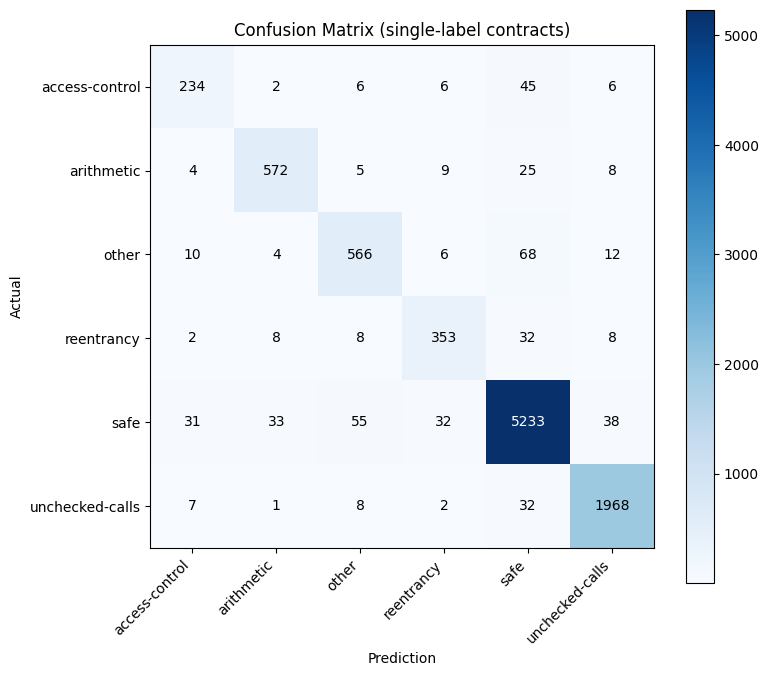

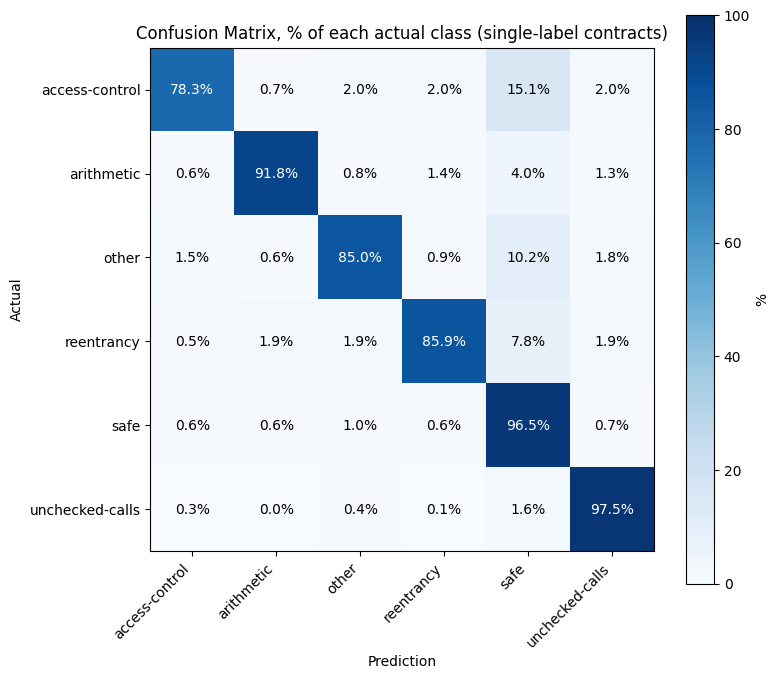

In [18]:


single = y_test.sum(axis=1) == 1
matrix = confusion_matrix(y_test[single].argmax(axis=1),
                          ensemble_test[single].argmax(axis=1),
                          labels=range(6))

plt.figure(figsize=(8, 7))
plt.imshow(matrix, cmap="Blues")
plt.xticks(range(6), LABELS, rotation=45, ha="right")
plt.yticks(range(6), LABELS)
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Confusion Matrix (single-label contracts)")
for i in range(6):
    for j in range(6):
        plt.text(j, i, matrix[i, j], ha="center", va="center",
                 color="white" if matrix[i, j] > matrix.max() / 2 else "black")
plt.colorbar()
plt.tight_layout()
plt.savefig(WORK + "confusion_matrix.png", dpi=200)
plt.show()
single = y_test.sum(axis=1) == 1
matrix = confusion_matrix(y_test[single].argmax(axis=1),
                          ensemble_test[single].argmax(axis=1),
                          labels=range(6))

# turn each row into percentages of that row's total
row_totals = matrix.sum(axis=1, keepdims=True)
percent = 100 * matrix / np.maximum(row_totals, 1)

plt.figure(figsize=(8, 7))
plt.imshow(percent, cmap="Blues", vmin=0, vmax=100)
plt.xticks(range(6), LABELS, rotation=45, ha="right")
plt.yticks(range(6), LABELS)
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Confusion Matrix, % of each actual class (single-label contracts)")
for i in range(6):
    for j in range(6):
        plt.text(j, i, "%.1f%%" % percent[i, j], ha="center", va="center",
                 color="white" if percent[i, j] > 50 else "black")
plt.colorbar(label="%")
plt.tight_layout()
plt.savefig(WORK + "confusion_matrix_percent.png", dpi=200)
plt.show()




In [ ]:
C_PREC = "#0072B2"   
C_REC = "#E69F00"    
C_F1 = "#009E73"    
C_HAM = "#7f7f7f"  

In [ ]:
our_p = 100 * precision_score(y_test, y_pred, average="macro", zero_division=0)
our_r = 100 * recall_score(y_test, y_pred, average="macro", zero_division=0)
our_f1 = 100 * f1_score(y_test, y_pred, average="macro", zero_division=0)
our_ham = hamming_loss(y_test, y_pred)

In [ ]:

studies = [
    ("[1] Optimized-CodeBERT\n(binary, mean of 4)", 93.95, 93.55, 93.53),
    ("[2] Hybrid-loss fusion\n(averaging n/a)", 92.38, 94.11, 93.24),
    ("[3] Transformer, 5 labels\n(weighted)", 73.00, 85.00, 79.00),
    ("[4] Ext-ttg, Wang 2024\n(micro)(peer js)", 85.57, 79.61, 82.48),
    ("[5] Random Forest, Ibba 2025\n(averaging n/a)(ext)", 89.00, 79.40, 83.90),
    ("MV-Stack (ours)\n(macro)", our_p, our_r, our_f1),
]

names = [s[0] for s in studies]
prec = [s[1] for s in studies]
rec = [s[2] for s in studies]
f1 = [s[3] for s in studies]


In [ ]:

x = np.arange(len(studies))
width = 0.26
BOTTOM = 40

plt.figure(figsize=(15, 6.5))
plt.axvspan(len(studies) - 1.5, len(studies) - 0.5, color="#eef3fb", zorder=0)
bars_p = plt.bar(x - width, np.array(prec) - BOTTOM, width, bottom=BOTTOM,
                 color=C_PREC, label="Precision", zorder=2)
bars_r = plt.bar(x, np.array(rec) - BOTTOM, width, bottom=BOTTOM,
                 color=C_REC, label="Recall", zorder=2)
bars_f = plt.bar(x + width, np.array(f1) - BOTTOM, width, bottom=BOTTOM,
                 color=C_F1, label="F1", zorder=2)

for group, values in [(bars_p, prec), (bars_r, rec), (bars_f, f1)]:
    for bar, value in zip(group, values):
        plt.text(bar.get_x() + bar.get_width() / 2, value + 0.5, "%.1f" % value,
                 ha="center", va="bottom", fontsize=8)

plt.xticks(x, names, fontsize=9)
plt.ylim(BOTTOM, 100)
plt.ylabel("Score (%%)  - axis starts at %d" % BOTTOM)
plt.title("Comparison with prior work", pad=30)
plt.legend(frameon=False, ncol=3, loc="lower center",
           bbox_to_anchor=(0.5, 1.0))          # above the plot, clear of the bars
plt.grid(axis="y", alpha=0.3, zorder=0)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(WORK + "comparison_prior_work.png", dpi=200)
plt.show()

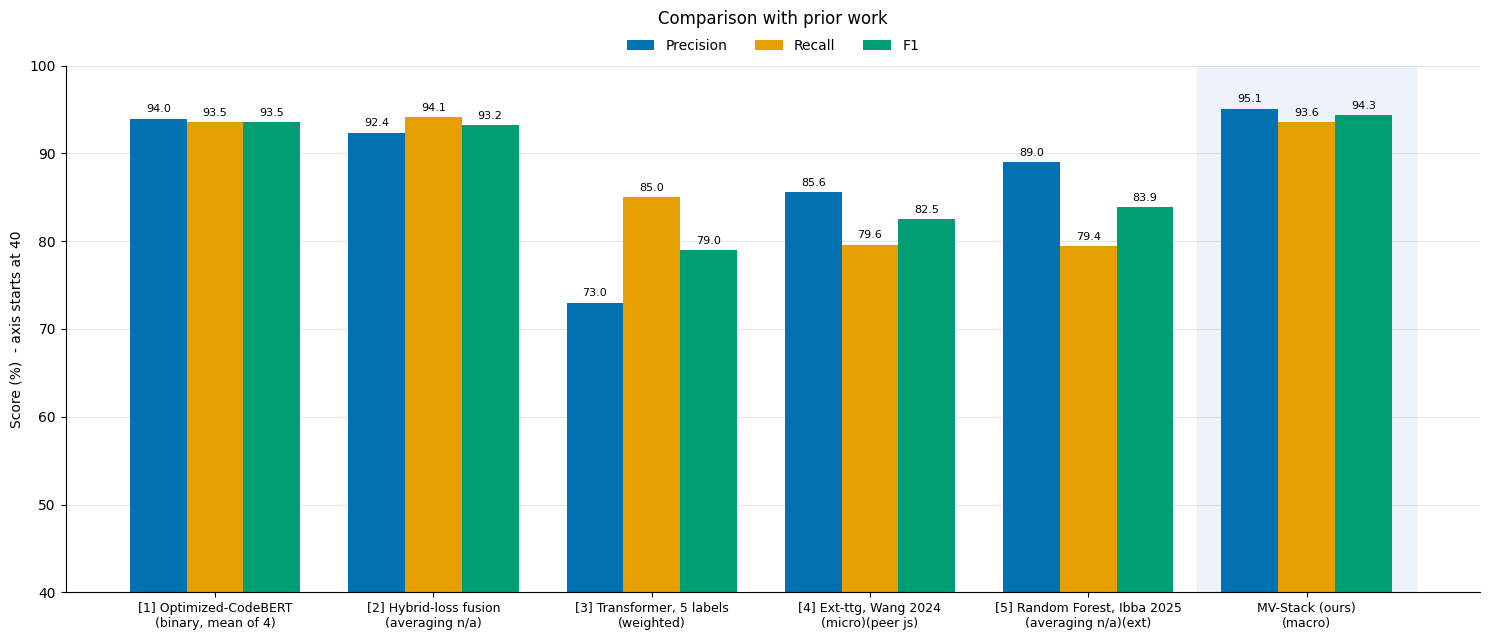

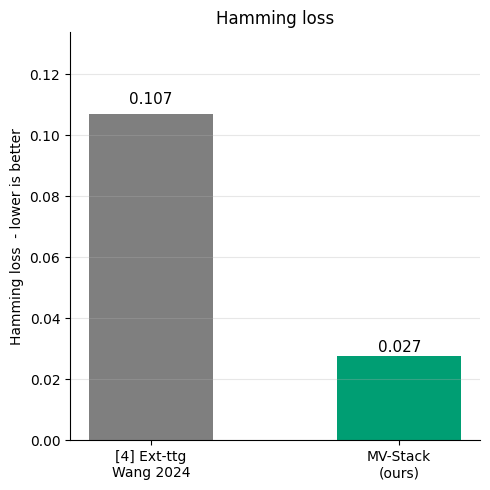

averaging   precision     recall         F1
macro           95.11      93.59      94.33
weighted        95.75      94.39      95.05
micro           95.74      94.39      95.06
hamming loss    : 0.0275
subset accuracy : 87.99


In [4]:
plt.figure(figsize=(5, 5))
bars = plt.bar(["[4] Ext-ttg\nWang 2024", "MV-Stack\n(ours)"], [0.107, our_ham],
               color=[C_HAM, C_F1], width=0.5)
for bar, value in zip(bars, [0.107, our_ham]):
    plt.text(bar.get_x() + bar.get_width() / 2, value * 1.02, "%.3f" % value,
             ha="center", va="bottom", fontsize=11)
plt.ylabel("Hamming loss  - lower is better")
plt.ylim(0, 0.107 * 1.25)
plt.title("Hamming loss")
plt.grid(axis="y", alpha=0.3)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(WORK + "comparison_hamming.png", dpi=200)
plt.show()

